# Analyze a Hippocampal Recording on a Maze

**Question:** Where do recorded neurons fire, and how does observed movement
relate to the maze's topology?

We follow one recording from verified download through graph-based rate maps
and endpoint-to-endpoint movement summaries. All analyses share one clock,
coordinate system and recording-gap rule.

**Estimated time**: 25-30 minutes

**Prerequisites**: [Spatial rate maps](02_spatial_rate_maps.ipynb) and
[Trajectories and behavior](03_trajectories_and_behavior.ipynb).

The public [J16 archive](https://doi.org/10.5281/zenodo.23020757) contains
203 hippocampal spike trains, preprocessed 500 Hz tracking and a track graph.
Positions are centimeters and timestamps are seconds. Tracking was already
smoothed, upsampled and linearized; this tutorial starts after preprocessing.
The archive does not retain original unit identifiers, task trials, rewards
or intended goals. Array indices identify units within this archive only.
See the [data guide](https://github.com/edeno/neurospatial/blob/main/data/README.md)
for study attribution, CC BY 4.0 licensing and preprocessing details.

In [1]:
import importlib.util
import itertools
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Circle

from neurospatial import Environment
from neurospatial.behavior import detect_region_crossings, path_progress
from neurospatial.encoding import compute_spatial_rates

_here = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
_root = next(
    path
    for path in (_here, *_here.parents)
    if (path / "data" / "load_bandit_data.py").exists()
)
sys.path.insert(0, str(_root / "examples"))
from _style import apply_style

apply_style(figsize=(10, 5))
_spec = importlib.util.spec_from_file_location(
    "load_bandit_data", _root / "data" / "load_bandit_data.py"
)
if _spec is None or _spec.loader is None:
    raise ImportError("Could not import the recording helper from data/.")
_loader = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(_loader)

## 1. Verify the recording and align its clock

The first run downloads about 75 MB. Later runs verify and reuse the cached
file. For offline work, run `uv run python data/load_bandit_data.py` beforehand.
Subtract the same origin from tracking and spikes; independently resetting
either clock would destroy their alignment.

In [2]:
archive = _loader.fetch_bandit_data(_root / "data")
recording = _loader.load_neural_recording_from_files(
    _root / "data", "j1620210710_02_r1"
)
tracking = recording["position_info"]
origin = float(tracking.index[0])
times = tracking.index.to_numpy(dtype=float) - origin
positions = tracking[["head_position_x", "head_position_y"]].to_numpy()
spike_times = [train - origin for train in recording["spike_times"]]
unit_ids = np.arange(len(spike_times))
spike_counts = np.array([len(train) for train in spike_times])
max_gap = 0.5  # seconds; the same rule is used for neural and behavioral analyses
recording_window = (float(times[0]), float(times[-1]))
print(f"Verified {archive.name}")
print(f"{len(times):,} samples, {len(unit_ids)} units, {times[-1] / 60:.1f} minutes")
print(f"Tracking gaps > {max_gap:g} s: {np.count_nonzero(np.diff(times) > max_gap)}")

Verified j1620210710_02_r1_figure04_inputs.npz
709,321 samples, 203 units, 23.6 minutes
Tracking gaps > 0.5 s: 0


## 2. Represent the known maze

Graph bins retain physical `(x, y)` coordinates and also have a linear track
coordinate. The inserted gaps in that linear display are not travel distance.
`bin_at` on a graph assigns finite positions to the nearest track-bin center;
it does not reject distant tracking outliers or resolve ambiguous branches
from movement history. We rely on the archived tracking preprocessing here.
The labeled orange circles are 8 cm endpoint proxies used in the transition
analysis below; they are operational annotations rather than surveyed wells.

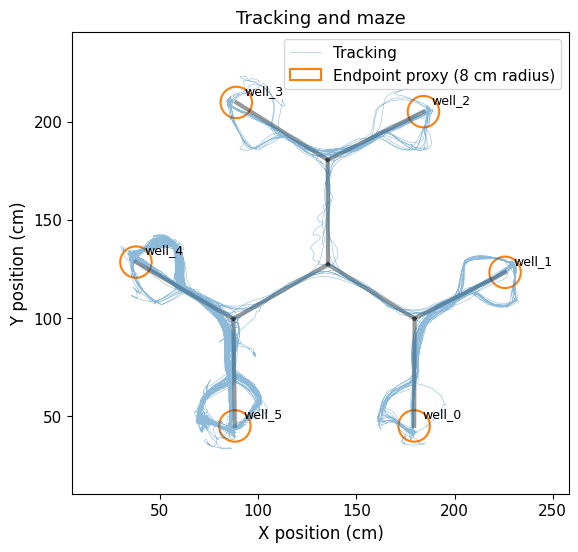

In [3]:
graph = recording["track_graph"]
env = Environment.from_graph(
    graph,
    edge_order=recording["linear_edge_order"],
    edge_spacing=recording["linear_edge_spacing"],
    bin_size=2.0,
    name="J16 maze",
)
env.units = "cm"
endpoint_nodes = sorted(node for node in graph if graph.degree(node) == 1)
well_radius_cm = 8.0
well_names = []
for node in endpoint_nodes:
    name = f"well_{node}"
    env.regions.buffer(
        np.asarray(graph.nodes[node]["pos"], dtype=float), well_radius_cm, name
    )
    well_names.append(name)

fig, ax = plt.subplots(figsize=(7, 6))
for first, second in graph.edges:
    segment = np.array([graph.nodes[first]["pos"], graph.nodes[second]["pos"]])
    ax.plot(*segment.T, color="black", linewidth=3, alpha=0.4)
ax.plot(
    *positions[::40].T, color="tab:blue", linewidth=0.4, alpha=0.5, label="Tracking"
)
for index, (node, name) in enumerate(zip(endpoint_nodes, well_names, strict=True)):
    center = np.asarray(graph.nodes[node]["pos"], dtype=float)
    ax.add_patch(
        Circle(
            center,
            well_radius_cm,
            fill=False,
            color="tab:orange",
            linewidth=1.5,
            label="Endpoint proxy (8 cm radius)" if index == 0 else None,
        )
    )
    ax.annotate(name, center, xytext=(6, 6), textcoords="offset points", fontsize=9)
ax.set(xlabel="X position (cm)", ylabel="Y position (cm)", title="Tracking and maze")
ax.margins(0.12)
ax.legend(loc="best")
ax.set_aspect("equal")
plt.show()

## 3. Estimate rates while retaining observation support

Use 8 cm graph diffusion and require 0.5 seconds of occupancy per bin. Missing
support remains NaN. These choices affect the estimated maps and should be
reported with the result; no cell-type or significance claim follows from a
visually localized rate map.

The archive has no per-unit acquisition intervals. We explicitly assume
continuous spike acquisition over the exported tracking epoch, supplied as
`spike_window`. Tracking continuity does not prove electrophysiology coverage;
replace this assumption with recorded acquisition windows when available.

In [4]:
rates = compute_spatial_rates(
    env,
    spike_times,
    times,
    positions,
    unit_ids=unit_ids,
    bandwidth=8.0,
    min_occupancy=0.5,
    max_gap=max_gap,
    spike_window=recording_window,
)
print(f"Observed tracking exposure: {rates.occupancy.sum():.1f} s")
print(f"Supported bins: {rates.spatial_support.sum()} / {env.n_bins}")
summary = pd.DataFrame(
    {
        "spike_count": spike_counts,
        "spatial_information_bits_per_spike": [
            rate.spatial_information() for rate in rates
        ],
    },
    index=pd.Index(rates.unit_ids, name="archive_unit_index"),
)
# Select by spike count for readable examples, without selecting on spatial tuning.
example_units = summary.nlargest(3, "spike_count").index.to_numpy()
print(summary.loc[example_units].round(3).to_string())

Observed tracking exposure: 1418.6 s
Supported bins: 173 / 248


                    spike_count  spatial_information_bits_per_spike
archive_unit_index                                                 
100                       63589                               0.028
178                       60932                               0.012
23                        56939                               0.027


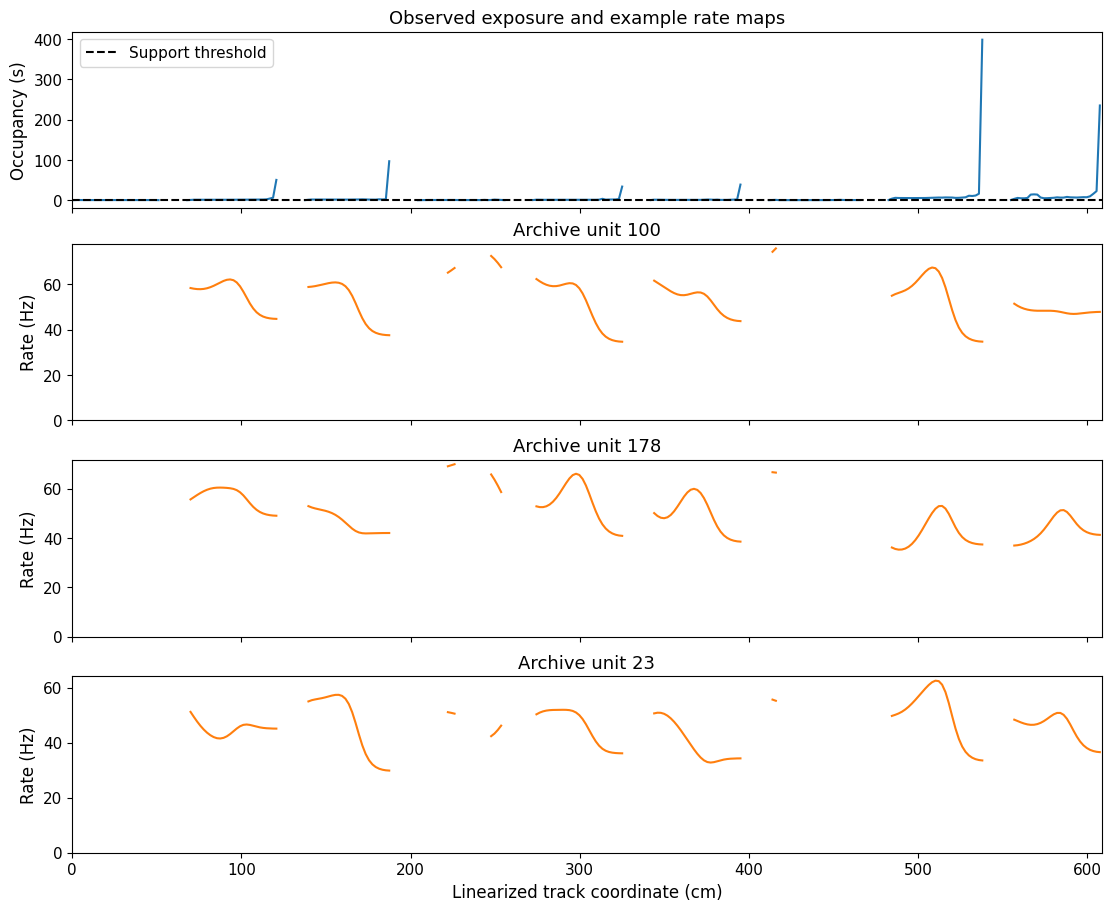

In [5]:
# Reinsert inactive display bins so lines do not bridge separate track segments.
edges = env.grid_edges[0]
linear_centers = (edges[:-1] + edges[1:]) / 2
active = env.active_mask.ravel()
np.testing.assert_allclose(linear_centers[active], env.to_linear(env.bin_centers))


def in_display_bins(values):
    """Keep artificial track-display gaps and missing support visibly missing."""
    expanded = np.full(linear_centers.shape, np.nan)
    expanded[active] = values
    return expanded


fig, axes = plt.subplots(4, 1, figsize=(11, 9), sharex=True, constrained_layout=True)
axes[0].plot(linear_centers, in_display_bins(rates.occupancy), color="tab:blue")
axes[0].axhline(0.5, color="black", linestyle="--", label="Support threshold")
axes[0].set(ylabel="Occupancy (s)", title="Observed exposure and example rate maps")
axes[0].legend()
for ax, unit_id in zip(axes[1:], example_units, strict=True):
    rate = rates.sel(unit_id=unit_id)
    ax.plot(linear_centers, in_display_bins(rate.firing_rate), color="tab:orange")
    ax.set(ylabel="Rate (Hz)", title=f"Archive unit {unit_id}", ylim=(0, None))
axes[-1].set(xlabel="Linearized track coordinate (cm)", xlim=(edges[0], edges[-1]))
plt.show()

## 4. Summarize observed endpoint transitions

Circles of radius 8 cm around degree-one graph nodes are operational well
proxies, not surveyed boundaries. Entries use track-bin membership. We pair
consecutive entries into different endpoints within one observed run. The
interval includes dwell time after the first entry; it is not a task trial or
a measured departure-to-arrival time. Changing the proxy radius changes events.

In [6]:
position_bins = env.bin_at(positions)
valid = (position_bins >= 0) & np.isfinite(positions).all(axis=1)
breaks = np.diff(times) > max_gap
starts = np.flatnonzero(valid & np.r_[True, ~valid[:-1] | breaks])
stops = np.flatnonzero(valid & np.r_[~valid[1:] | breaks, True]) + 1
visits = []
for run_id, (start, stop) in enumerate(zip(starts, stops, strict=True)):
    for name in well_names:
        for crossing in detect_region_crossings(
            position_bins[start:stop],
            times[start:stop],
            env,
            region_name=name,
            direction="entry",
            max_gap=max_gap,
        ):
            visits.append((int(np.searchsorted(times, crossing.time)), name, run_id))
visits.sort()
transitions = [
    (first, second)
    for first, second in itertools.pairwise(visits)
    if first[1] != second[1] and first[2] == second[2]
]
if not transitions:
    raise ValueError(
        "No between-endpoint transitions; inspect the tracking and regions."
    )
counts = Counter((first[1], second[1]) for first, second in transitions)
transition_table = pd.DataFrame(
    [(start, destination, count) for (start, destination), count in counts.items()],
    columns=["start", "next_endpoint", "count"],
).sort_values("count", ascending=False)
print(f"{len(visits)} entries; {len(transitions)} between-endpoint transitions")
print(transition_table.to_string(index=False))

191 entries; 180 between-endpoint transitions
 start next_endpoint  count
well_5        well_4     63
well_4        well_5     62
well_1        well_0     14
well_0        well_1     14
well_2        well_3      9
well_3        well_2      8
well_2        well_1      2
well_1        well_4      2
well_4        well_1      2
well_4        well_2      1
well_1        well_5      1
well_1        well_2      1
well_3        well_4      1


## 5. Inspect normalized displacement along the graph

`path_progress` is clipped distance-from-start divided by start-to-destination
distance. On a branched maze a detour can reach 1, so 1 alone does not prove
arrival or efficient travel. Here the observed entry bins supply both reference
endpoints. Include both entry samples, preserving values 0 and 1; adjacent
transitions share an entry timestamp but have separate progress curves.

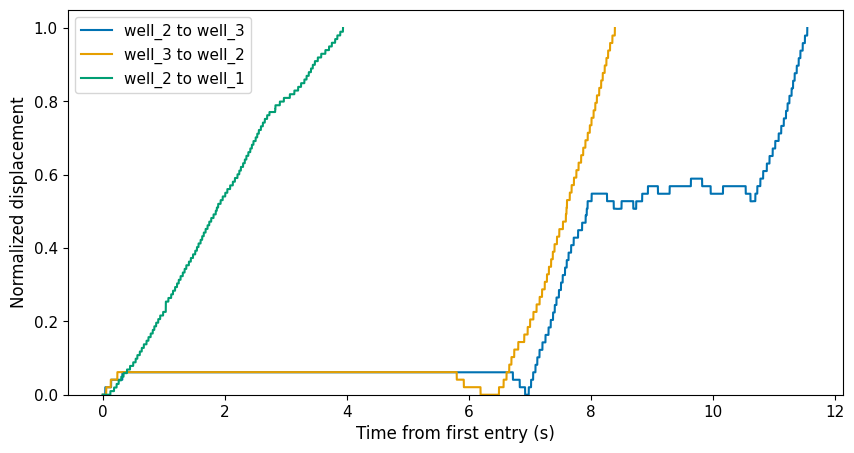

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
for first, second in transitions[:3]:
    first_index, start_name, _ = first
    last_index, destination_name, _ = second
    selected = np.arange(first_index, last_index + 1)
    assert np.all(valid[selected]) and np.all(np.diff(times[selected]) <= max_gap)
    progress = path_progress(
        position_bins[selected],
        env,
        start_bins=np.full(selected.size, position_bins[first_index]),
        goal_bins=np.full(selected.size, position_bins[last_index]),
        metric="geodesic",
    )
    np.testing.assert_allclose(progress[[0, -1]], [0.0, 1.0])
    ax.plot(
        times[selected] - times[first_index],
        progress,
        label=f"{start_name} to {destination_name}",
    )
ax.set(
    xlabel="Time from first entry (s)", ylabel="Normalized displacement", ylim=(0, 1.05)
)
ax.legend()
plt.show()

We obtained supported rate maps for labeled archive units and descriptive
movement summaries from the same recording. Stronger claims require extra
evidence: spike-sorting metadata for cell identity, task logs for trials and
rewards, and a justified null for tuning significance.

Next, use [held-out decoding](06_position_decoding.ipynb) to evaluate prediction
on new observations or [peri-event analysis](07_peri_event_analysis.ipynb) to
align spikes to independently defined events.